In [1]:
import socket
from pyspark.sql import SparkSession

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pyspark.sql.functions as F
import seaborn as sns

import os
import sys

In [2]:
spark = SparkSession.builder.getOrCreate()

spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")

print("Running on:   ", socket.gethostname())
print("Spark master: ", spark.sparkContext.master)
print("Spark version:", spark.version)

Running on:    rainfall-dev-m
Spark master:  yarn
Spark version: 3.5.3


In [3]:
## Constants
sns.set_theme()
path = "./HistoricalRainfallacrossSingapore"

C_LAT, C_LON = 1.3521, 103.8198 
RF_MULTIPLIER = (24 * 60) / 5

In [ ]:
!gcloud storage ls gs://dsa5208-rainfall-sixing-data/raw/

gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2017).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2018).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2019).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2020).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2021).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2022).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2023).csv
gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore (2024).csv


In [5]:
DATA = "gs://dsa5208-rainfall-sixing-data/raw/Historical Rainfall across Singapore*.csv"

rain = spark.read.csv(DATA, header=True)
rain.printSchema()
rain.show(5, truncate=False)
print("Rows:", rain.count())

root
 |-- date: string (nullable = true)
 |-- timestamp: string (nullable = true)
 |-- update_timestamp: string (nullable = true)
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: string (nullable = true)
 |-- location_latitude: string (nullable = true)
 |-- reading_update_timestamp: string (nullable = true)
 |-- reading_value: string (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)



+----------+-------------------------+-------------------------+----------+-------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|date      |timestamp                |update_timestamp         |station_id|station_name       |station_device_id|location_longitude|location_latitude|reading_update_timestamp |reading_value|reading_type                 |reading_unit|
+----------+-------------------------+-------------------------+----------+-------------------+-----------------+------------------+-----------------+-------------------------+-------------+-----------------------------+------------+
|2017-01-01|2017-01-01T08:04:59+08:00|2017-01-01T08:13:31+08:00|S77       |Alexandra Road     |S77              |103.8125          |1.2937           |2017-01-01T08:13:31+08:00|0.0          |TB1 Rainfall 5 Minute Total F|mm          |
|2017-01-01|2017-01-01T08:04:59+08:00|2017-01-01T08:13:31+08:00|

Rows: 48538713


In [6]:
df = spark.read.option("header", True).csv(DATA)
df = df.withColumn("date", F.to_date("date", "yyyy-MM-dd"))
df = df.withColumn("year", F.year("date")).withColumn("month", F.month("date"))

monthly_spk = (df.groupBy("year", "month")
    .agg(F.avg("reading_value").alias("mean_per_interval"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("year_month", F.make_date("year", "month", F.lit(1)))
    .withColumn("days", F.dayofmonth(F.last_day("year_month")))
    .withColumn("avg_rainfall_monthly",
                F.col("mean_per_interval") * F.col("days") * RF_MULTIPLIER)
    .orderBy("year_month"))

In [7]:
monthly_df = monthly_spk.toPandas()
monthly_df

,year,month,mean_per_interval,n_stations,year_month,days,avg_rainfall_monthly
0,2017,1,0.027649,58,2017-01-01,31,246.847136
1,2017,2,0.018776,58,2017-02-01,28,151.410304
2,2017,3,0.020656,59,2017-03-01,31,184.414851
3,2017,4,0.028492,55,2017-04-01,30,246.170041
4,2017,5,0.026978,52,2017-05-01,31,240.860586
...,...,...,...,...,...,...,...
91,2024,8,0.014338,63,2024-08-01,31,128.012822
92,2024,9,0.026012,62,2024-09-01,30,224.740843
93,2024,10,0.021529,62,2024-10-01,31,192.209064
94,2024,11,0.048195,64,2024-11-01,30,416.407206


<Figure size 1600x1000 with 0 Axes>

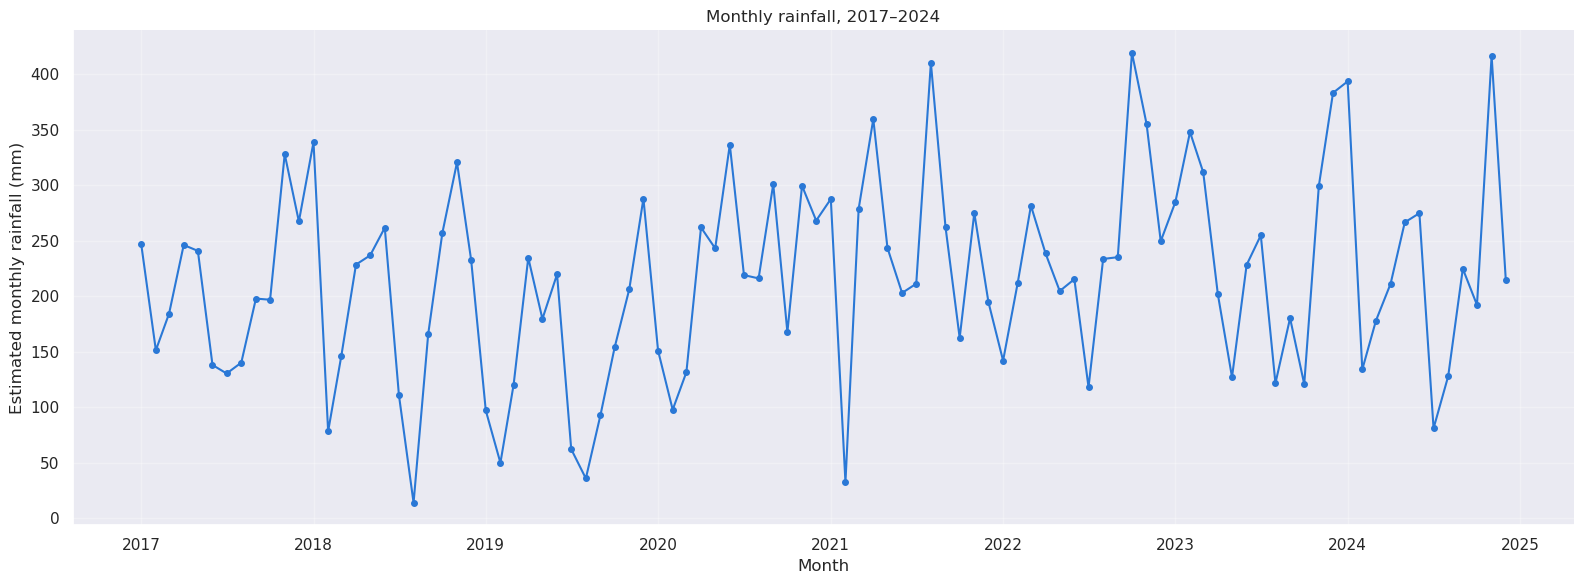

In [8]:
plt.figure(figsize=(16, 10))

monthly_df = monthly_df.sort_values("year_month")

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(monthly_df["year_month"], monthly_df["avg_rainfall_monthly"],
        marker="o", markersize=4, linewidth=1.5, color="#2a78d6")

ax.set_xlabel("Month")
ax.set_ylabel("Estimated monthly rainfall (mm)")
ax.set_title("Monthly rainfall, 2017–2024")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
ax.grid(True, alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [9]:
annual_spk = (df.groupBy("year")
    .agg(F.avg("reading_value").alias("mean_per_interval"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("days", F.when(F.col("year") % 4 == 0, 366).otherwise(365))
    .withColumn("est_annual_mm",
                F.col("mean_per_interval") * F.col("days") * 288)
    .orderBy("year"))

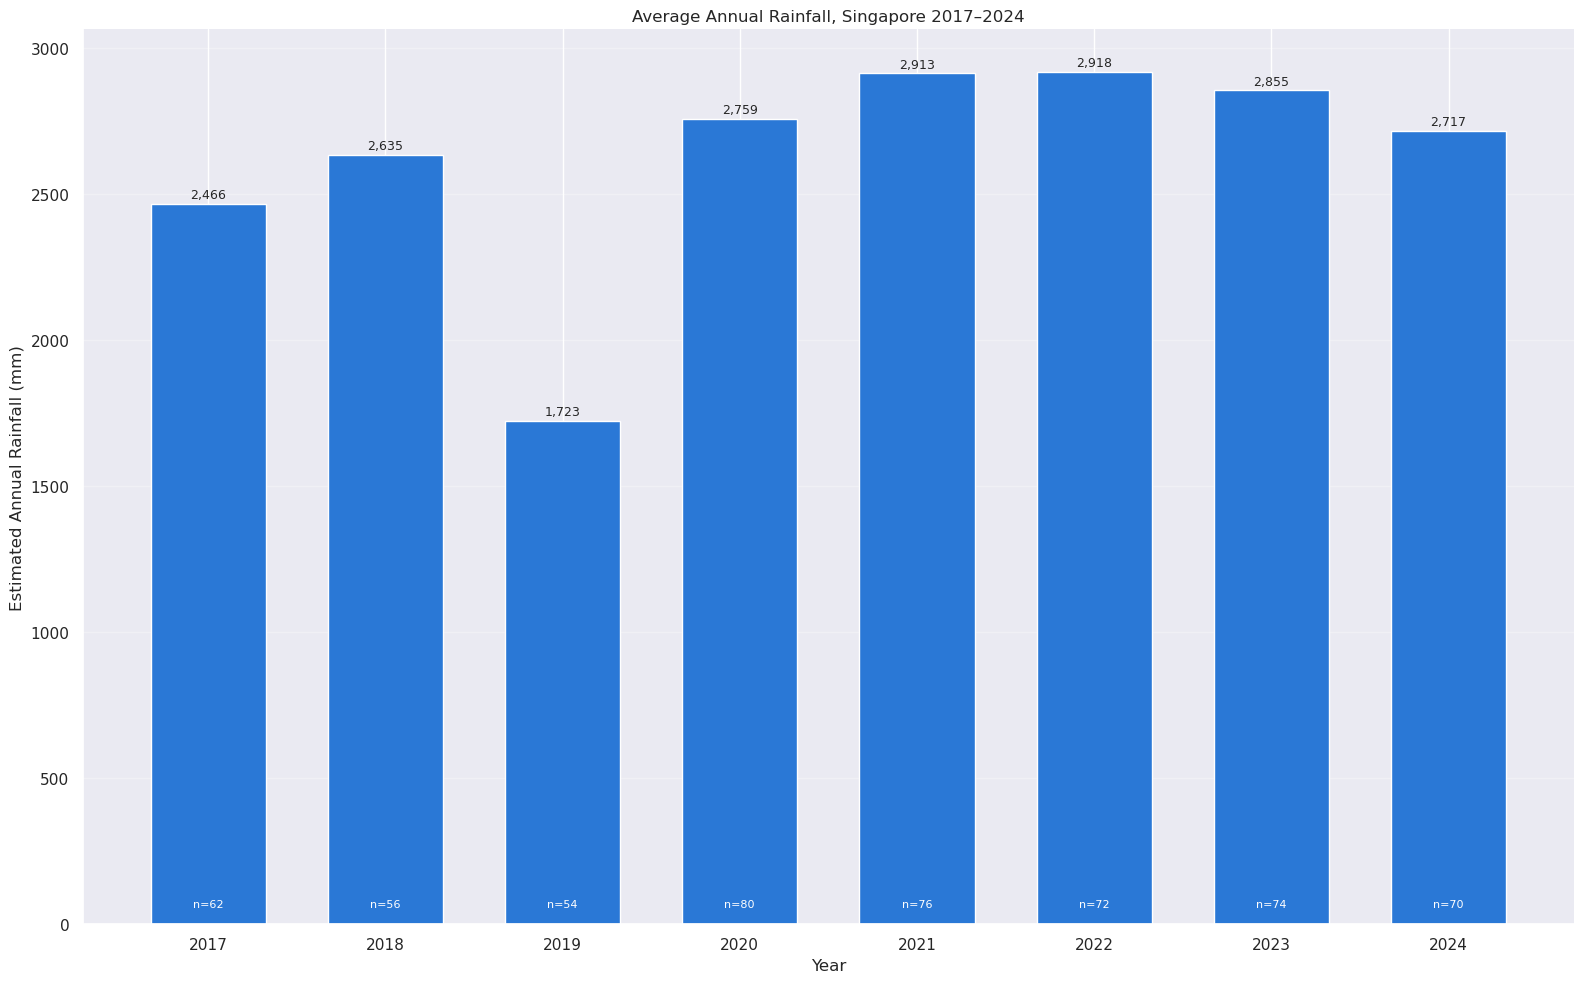

In [10]:
annual_df = annual_spk.toPandas()

fig, ax = plt.subplots(figsize=(16, 10))
bars = ax.bar(annual_df["year"], annual_df["est_annual_mm"],
              color="#2a78d6", width=0.65)

ax.set_xlabel("Year")
ax.set_ylabel("Estimated Annual Rainfall (mm)")
ax.set_title("Average Annual Rainfall, Singapore 2017–2024")
ax.set_xticks(annual_df["year"])
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for b, v, n in zip(bars, annual_df["est_annual_mm"], annual_df["n_stations"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v:,.0f}",
            ha="center", fontsize=9)
    ax.text(b.get_x() + b.get_width() / 2, 60, f"n={n}",
            ha="center", fontsize=8, color="white")

plt.tight_layout()

### Region Test

In [11]:
stations_spk = df.select("station_id", "station_name", "location_latitude", "location_longitude").distinct()

In [12]:
stations_df = stations_spk.toPandas()
stations_df

,station_id,station_name,location_latitude,location_longitude
0,S106,Pulau Ubin,1.4168,103.9673
1,S114,Choa Chu Kang Avenue 4,1.38,103.73
2,S08,Upper Thomson Road,1.3701,103.8271
3,S36,Upper Serangoon Road,1.3382,103.8657
4,S06,S06,1.3524,103.9007
...,...,...,...,...
114,S210,Woodlands Centre,1.44003,103.76904
115,S207,Bedok Road,1.32485,103.95836
116,S216,Ang Mo Kio Avenue 10,1.36019,103.85335
117,S221,Hougang Avenue 1,1.35691,103.89088


In [13]:
stations_spk = df.select("station_id", "station_name", "location_latitude", "location_longitude").distinct()

stations = (stations_spk
    .withColumn("dy", F.col("location_latitude") - F.lit(C_LAT))
    .withColumn("dx", F.col("location_longitude") - F.lit(C_LON))
    .withColumn("dist", F.sqrt(F.col("dx")**2 + F.col("dy")**2))
    .withColumn("bearing", F.degrees(F.atan2("dx", "dy")))  # 0=N, 90=E
    .withColumn("region",
        F.when(F.col("dist") < 0.045, "Central")
         .when((F.col("bearing") >= -45) & (F.col("bearing") < 45), "North")
         .when((F.col("bearing") >= 45) & (F.col("bearing") < 135), "East")
         .when((F.col("bearing") >= -135) & (F.col("bearing") < -45), "West")
         .otherwise("South")))

In [14]:
region_spk = df.join(stations.select("station_id", "region"), on="station_id", how="left")

In [15]:
station_monthly = (region_spk
    .groupBy("station_id", "region", "year", "month")
    .agg(F.sum("reading_value").alias("monthly_mm")))

region_monthly = (station_monthly
    .groupBy("region", "year", "month")
    .agg(F.avg("monthly_mm").alias("avg_mm"),
         F.countDistinct("station_id").alias("n_stations"))
    .withColumn("ym", F.make_date("year", "month", F.lit(1)))
    .orderBy("ym", "region"))

region_df = region_monthly.toPandas()

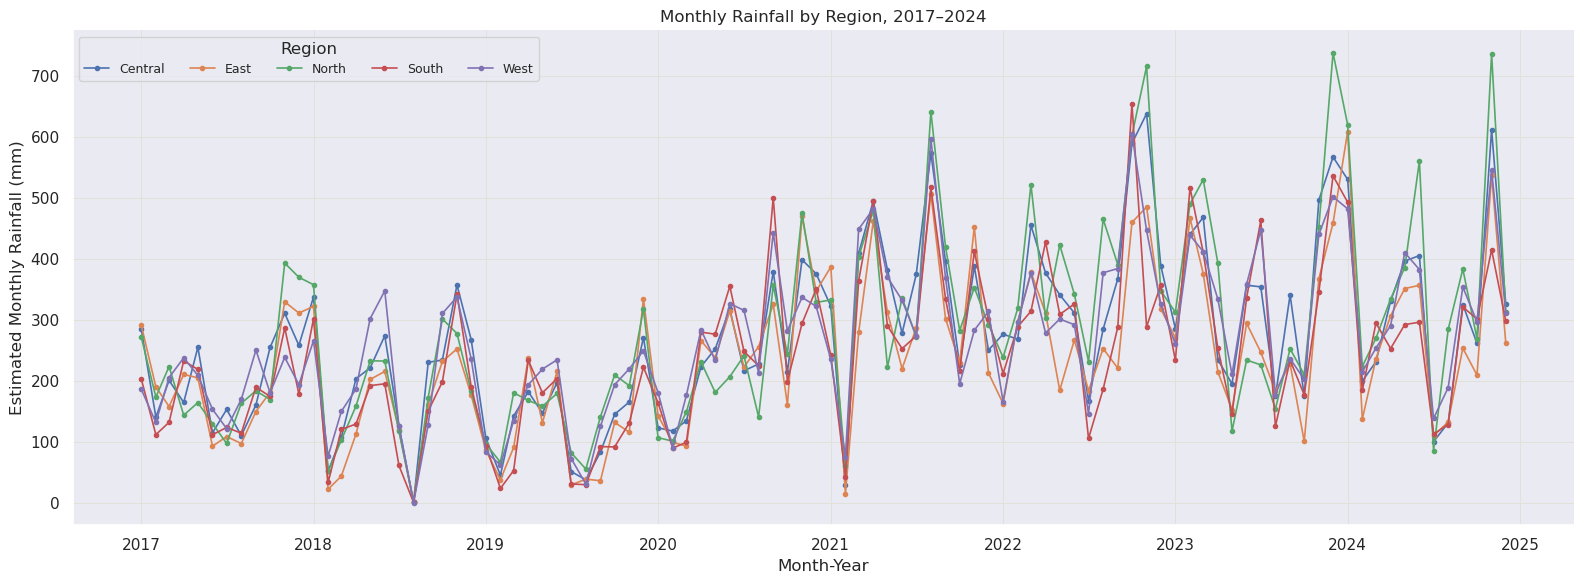

In [16]:
region_df = region_df.sort_values("ym")
wide = region_df.pivot(index="ym", columns="region", values="avg_mm")

fig, ax = plt.subplots(figsize=(16, 6))
wide.plot(ax=ax, marker="o", markersize=3, linewidth=1.2)

ax.set_xlabel("Month-Year")
ax.set_ylabel("Estimated Monthly Rainfall (mm)")
ax.set_title("Monthly Rainfall by Region, 2017–2024")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(which="major", axis="both", color="#e1e0d9", linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Region", ncol=5, fontsize=9)
plt.tight_layout()

array([<Axes: xlabel='ym'>, <Axes: xlabel='ym'>, <Axes: xlabel='ym'>,
       <Axes: xlabel='ym'>, <Axes: xlabel='ym'>], dtype=object)

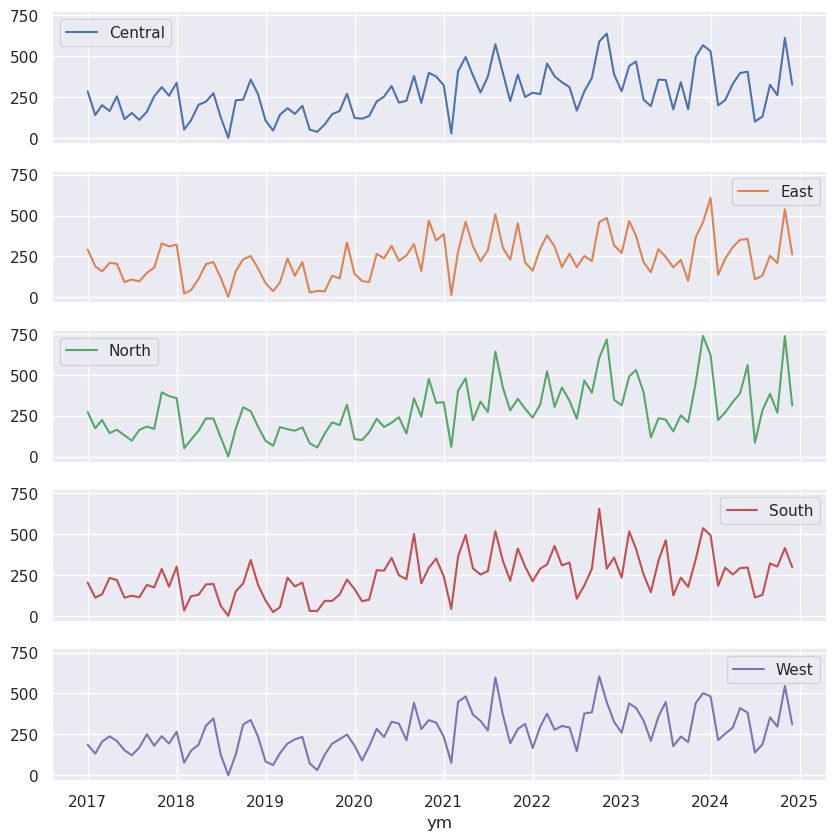

In [17]:
# (b) full series as small multiples instead of overlaid
wide = region_df.pivot(index="ym", columns="region", values="avg_mm")
wide.plot(subplots=True, figsize=(10,10), sharex=True, sharey=True)

In [18]:
stations.groupBy("region").agg(F.count("*").alias("n"),
         F.round(F.avg("location_latitude"), 4).alias("mean_lat"),
         F.round(F.avg("location_longitude"), 4).alias("mean_lon")).orderBy(F.desc("n")).show()

+-------+---+--------+--------+
| region|  n|mean_lat|mean_lon|
+-------+---+--------+--------+
|   East| 40|  1.3467|103.9229|
|   West| 28|  1.3407|103.7187|
|  South| 19|  1.2819|103.8106|
|Central| 17|  1.3456|103.8302|
|  North| 15|   1.431|103.7987|
+-------+---+--------+--------+



### Heatmap Per Month

In [19]:
hm = (df
    .withColumn("hour", F.hour("timestamp"))
    .groupBy("month", "hour")
    .agg(F.avg("reading_value").alias("mean_mm"),
         F.count("*").alias("n"))
    .orderBy("month", "hour"))

hm_df = hm.toPandas()
grid = hm_df.pivot(index="hour", columns="month", values="mean_mm")

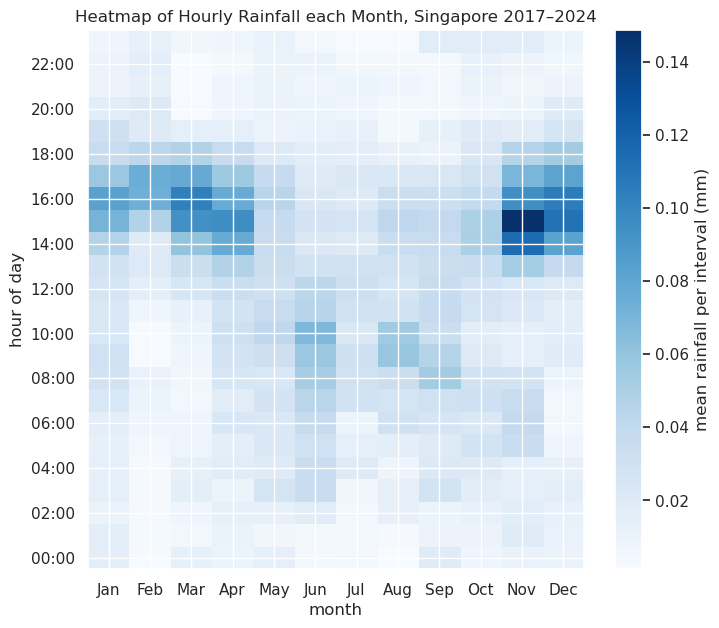

In [20]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues")
ax.set_title("Heatmap of Hourly Rainfall each Month, Singapore 2017–2024")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_xlabel("month"); ax.set_ylabel("hour of day")
fig.colorbar(im, label="mean rainfall per interval (mm)")

In [21]:
df.select("timestamp").show(5, truncate=False)

+-------------------------+
|timestamp                |
+-------------------------+
|2017-01-01T08:04:59+08:00|
|2017-01-01T08:04:59+08:00|
|2017-01-01T08:04:59+08:00|
|2017-01-01T08:04:59+08:00|
|2017-01-01T08:04:59+08:00|
+-------------------------+
only showing top 5 rows

